# Checkpoint 2: Calibration dan Selective Fusion untuk Visual PEFT

**Kelompok 1** · Alif Negifta Wibawaputra dan Charleen Samaeri Gulo  
**Mentor** · Husein Sidharta Muhammad

Kelanjutan dari [Checkpoint 1: Visual PEFT pada Flowers102](01_flowers102_checkpoint1.ipynb).
Notebook ini menggabungkan baseline, pilot, dan evaluasi lintas training seed pada development validation.

[Pertanyaan riset](#research) · [Dataset dan metode](#datasets) · [Baseline](#baseline) · [Pilot](#pilot) · [Evaluasi tiga training seed](#training-seeds) · [Diskusi](#discussion) · [Reproduksi](#reproduction)

<a id="research"></a>
## 1. Pertanyaan riset

Kapan menjalankan expert kedua dengan confidence gate memberi kualitas prediksi yang sebanding dengan always-on averaging? Kami membandingkan accuracy, NLL, Brier, dan frekuensi fallback. Temperature scaling dan confidence routing menjadi baseline untuk studi empiris tentang perbedaan prediksi antar-metode PEFT.

<a id="datasets"></a>
## 2. Dataset dan metode

| Dataset | Tugas | Train | Validation dianalisis | Kelas validation |
|---|---|---:|---:|---:|
| Flowers102 | Klasifikasi bunga | 800 | 200 | 90/102 |
| DTD | Klasifikasi tekstur | 800 | 199 | 47/47 |
| RESISC45 | Klasifikasi scene citra udara | 800 | 200 | 45/45 |
| SVHN | Klasifikasi digit | 800 | 200 | 10/10 |
| PatchCamelyon | Klasifikasi patch histopatologi | 800 | 200 | 2/2 |

Satu gambar validation DTD yang identik dengan gambar training dikeluarkan. Pemisahan patient atau slide pada mirror PatchCamelyon belum terverifikasi.

Semua expert memakai ViT-B/16 pretrained ImageNet-21K dan checkpoint epoch 100. Linear hanya melatih classifier. LoRA dan FacT-TT memakai faktorisasi, SSF mengubah skala dan pergeseran fitur, ConvPass dan AdaptFormer menambah adapter, VPT-Deep menambah prompt, dan BitFit melatih bias serta classifier. Resep kapasitas dan optimizer bervariasi antar-metode. Perbandingan mengukur resep secara keseluruhan.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "results/checkpoint2/manifest.json").is_file():
    ROOT = ROOT.parent
RESULTS = ROOT / "results/checkpoint2"
FIGURES = ROOT / "assets/checkpoint2"
if not (RESULTS / "manifest.json").is_file():
    raise FileNotFoundError("Buka dari root repo atau folder notebooks dengan artefak Checkpoint 2.")

manifest = json.loads((RESULTS / "manifest.json").read_text())
assert manifest["evaluation"] == "development_validation" and not manifest["final_test_used"]
for relpath, digest in manifest["output_sha256"].items():
    if hashlib.sha256((ROOT / relpath).read_bytes()).hexdigest() != digest:
        raise ValueError(f"Artefak berbeda dari manifest: {relpath}")

NAMES = {"oxford_flowers102": "Flowers102", "dtd": "DTD", "resisc45": "RESISC45",
         "svhn": "SVHN", "patch_camelyon": "PatchCamelyon", "linear": "Linear",
         "lora": "LoRA", "ssf": "SSF", "convpass": "ConvPass"}
def read_csv(path):
    return pd.read_csv(RESULTS / path)

<a id="baseline"></a>
## 3. Baseline pada training seed 42

Heatmap menunjukkan accuracy validation dari 40 kombinasi dataset dan metode. NLL, Brier, macro recall, jumlah parameter, serta resep per run tersedia di [tabel baseline](../results/checkpoint2/baselines/metrics.csv) dan [tabel konfigurasi](../results/checkpoint2/baselines/recipes.csv). [Learning curves setiap epoch](../results/checkpoint2/baselines/learning_curves.csv) tersedia untuk seluruh run. Skor probabilitas dibandingkan di dalam dataset karena jumlah kelas berbeda.

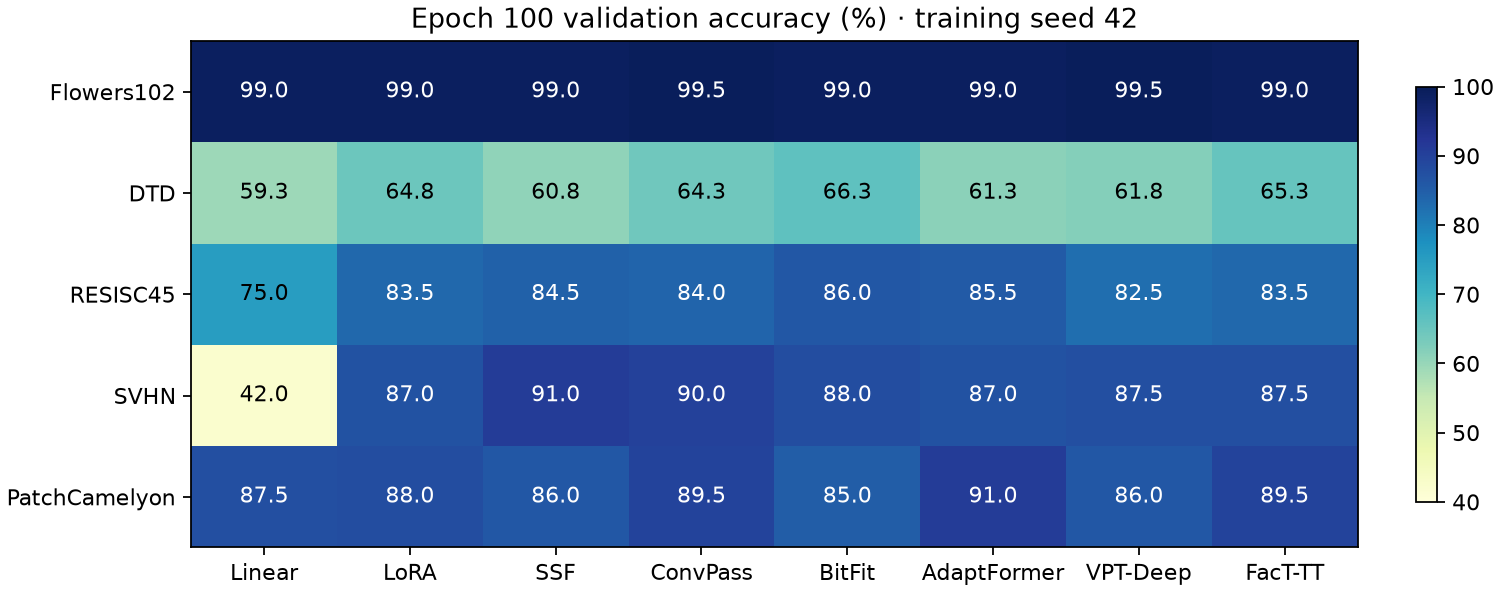

In [2]:
baseline = read_csv("baselines/metrics.csv")
assert len(baseline) == manifest["baseline_count"] == 40
display(Image(filename=str(FIGURES / "baseline_accuracy.png")))

<a id="pilot"></a>
## 4. Pilot calibration dan selective fusion

Pilot awal menguji Linear → LoRA di DTD dan RESISC45. Random routing awal menyamakan **budget secara ekspektasi**. Pilot gabungan menambah SVHN dan PatchCamelyon, menguji keenam pasangan Linear, LoRA, SSF, dan ConvPass dalam dua arah, dan menyamakan **jumlah fallback aktual per fold** pada pembanding random.

Kedua pilot memakai **training seed 42**. Temperature dipilih dengan minimisasi NLL pada empat dari lima fold. Prediksi dinilai pada fold tersisa. Pembagian diulang dengan seed 42, 43, dan 44. Tabel di bawah memilih konfigurasi selective dengan mean NLL terendah pada setiap dataset. Karena dipilih dari validation yang sama, tabel berfungsi sebagai dasar hipotesis.

**Kontribusi tim.** Gipta membangun pipeline bersama dan menguji pasangan antara Linear, LoRA, dan SSF. Charleen menguji pasangan yang melibatkan ConvPass dan menulis analisisnya. Rekap dan cross-check di bawah berasal dari artefak kedua kontributor.

In [3]:
pilot = read_csv("pilot/selected_candidates.csv")
pilot["Dataset"] = pilot.dataset.map(NAMES)
pilot["Arah"] = pilot.first_method.map(NAMES) + " → " + pilot.second_method.map(NAMES)
pilot["Accuracy (%)"] = 100 * pilot.accuracy_mean
pilot["Fallback aktual (%)"] = 100 * pilot.fallback_fraction_mean
display(pilot[["Dataset", "Arah", "Accuracy (%)", "Fallback aktual (%)", "nll_mean",
               "always_on_nll", "matched_random_nll"]].rename(columns={
                   "nll_mean": "NLL selective", "always_on_nll": "NLL always-on",
                   "matched_random_nll": "NLL random"}).round(4).reset_index(drop=True))

averaging = read_csv("pilot/averaging_comparison.csv").set_index("contributor")
scale = read_csv("pilot/calibration_summary.csv").pivot(
    index=["dataset", "method"], columns="stage", values=["nll_mean", "brier_mean"])
improved = lambda metric: int((scale[metric].temperature_scaled_oof < scale[metric].raw_oof).sum())
display(Markdown(
    f"Temperature scaling menurunkan NLL pada **{improved('nll_mean')}/{len(scale)}** kombinasi "
    f"dan Brier pada **{improved('brier_mean')}/{len(scale)}**. "
    f"Averaging menghasilkan NLL lebih rendah daripada replacement pada "
    f"**{averaging.loc['team', 'averaging_lower_nll']}/{averaging.loc['team', 'matched_configurations']}** "
    f"perbandingan gabungan. Bagian Charleen mencakup "
    f"**{averaging.loc['charleen', 'averaging_lower_nll']}/{averaging.loc['charleen', 'matched_configurations']}**."
))
cross = read_csv("pilot/cross_checks.csv")
cross["Pemeriksa"] = cross.reviewer.str.capitalize()
cross["Dataset"] = cross.dataset.map(NAMES)
cross["Accuracy (%)"] = 100 * cross.accuracy
cross["Fallback aktual (%)"] = 100 * cross.fallback_fraction
display(cross[["Pemeriksa", "Dataset", "n", "Accuracy (%)", "Fallback aktual (%)"]])

,Dataset,Arah,Accuracy (%),Fallback aktual (%),NLL selective,NLL always-on,NLL random
0,PatchCamelyon,ConvPass → Linear,90.0000,25.8333,0.2293,0.2549,0.2573
1,SVHN,ConvPass → SSF,91.5000,25.3333,0.2964,0.3086,0.3200
2,RESISC45,ConvPass → SSF,86.5000,74.1667,0.5161,0.5206,0.5307
3,DTD,LoRA → SSF,64.9916,74.8744,1.2423,1.2414,1.2681


Temperature scaling menurunkan NLL pada **16/16** kombinasi dan Brier pada **13/16**. Averaging menghasilkan NLL lebih rendah daripada replacement pada **110/144** perbandingan gabungan. Bagian Charleen mencakup **56/72**.

,Pemeriksa,Dataset,n,Accuracy (%),Fallback aktual (%)
0,Gipta,PatchCamelyon,200,89.5,51.0
1,Charleen,SVHN,200,88.5,51.0


<a id="training-seeds"></a>
## 5. Evaluasi tiga training seed

Pasangan dikunci pada **SVHN ConvPass → SSF** dan **PatchCamelyon ConvPass → Linear**, dengan averaging berbobot sama dan target fallback 25%. Setiap pasangan dinilai pada training seed 42, 43, dan 44 ketika kedua logits epoch 100 tersedia. Recipe tiap model tetap sama pada ketiga training seed.

Metrik per training seed adalah mean dari tiga pembagian calibration dengan split seed 42, 43, dan 44. Random routing dirata-ratakan pada 20 random seed setiap pembagian sebelum diringkas. File metrik menyimpan SD antar-pembagian. Mean dan SD **antar-training seed** hanya dihitung ketika ketiga training seed lengkap. Semua hasil masih menggunakan development validation.

In [4]:
availability = read_csv("confirmation/availability.csv").fillna("")
scores = read_csv("confirmation/metrics_by_training_seed.csv")
assert len(availability) == 6
availability["Dataset"] = availability.dataset.map(NAMES)
availability["Status"] = availability.status.map({"evaluated": "Dievaluasi", "incomplete": "Belum lengkap"})
availability["Artefak belum tersedia"] = availability.missing_epoch100_artifact.map(NAMES).fillna("")
display(availability[["Dataset", "training_seed", "Status", "Artefak belum tersedia"]].rename(
    columns={"training_seed": "Training seed"}))
assert len(scores) == 5 * manifest["confirmation_pairs_evaluated"]

/tmp/ipykernel_52802/354633086.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  availability = read_csv("confirmation/availability.csv").fillna("")


,Dataset,Training seed,Status,Artefak belum tersedia
0,SVHN,42,Dievaluasi,
1,SVHN,43,Dievaluasi,
2,SVHN,44,Dievaluasi,
3,PatchCamelyon,42,Dievaluasi,
4,PatchCamelyon,43,Dievaluasi,
5,PatchCamelyon,44,Dievaluasi,


### SVHN

,Training seed,Strategi,Accuracy (%),NLL,Brier,Fallback aktual (%)
0,42,Expert pertama,90.0000,0.3249,0.1391,0.0000
1,42,Expert kedua,91.0000,0.3456,0.1474,0.0000
2,42,Always-on,91.5000,0.3086,0.1279,100.0000
3,42,Selective,91.5000,0.2964,0.1234,25.3333
4,42,Matched random,90.4667,0.3200,0.1357,25.3333
5,43,Expert pertama,92.0000,0.2974,0.1205,0.0000
6,43,Expert kedua,90.5000,0.3422,0.1411,0.0000
7,43,Always-on,92.5000,0.2934,0.1182,100.0000
8,43,Selective,92.5000,0.2787,0.1133,25.6667
9,43,Matched random,92.1250,0.2964,0.1194,25.6667


### PatchCamelyon

,Training seed,Strategi,Accuracy (%),NLL,Brier,Fallback aktual (%)
0,42,Expert pertama,89.5000,0.2605,0.1542,0.0000
1,42,Expert kedua,87.5000,0.3030,0.1907,0.0000
2,42,Always-on,90.0000,0.2549,0.1481,100.0000
3,42,Selective,90.0000,0.2293,0.1313,25.8333
4,42,Matched random,89.6583,0.2573,0.1515,25.8333
5,43,Expert pertama,91.0000,0.2433,0.1372,0.0000
6,43,Expert kedua,87.0000,0.3008,0.1891,0.0000
7,43,Always-on,89.5000,0.2452,0.1423,100.0000
8,43,Selective,89.5000,0.2466,0.1400,26.5000
9,43,Matched random,90.5750,0.2444,0.1385,26.5000


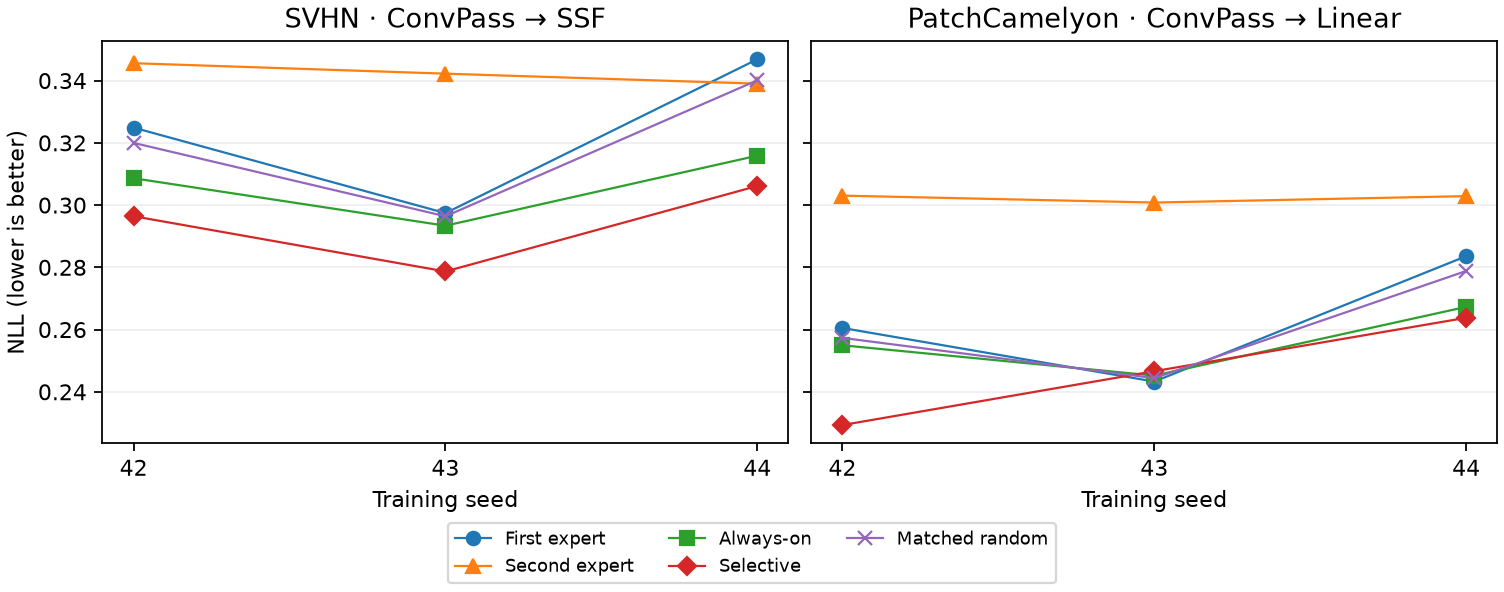

In [5]:
labels = {"calibrated_first": "Expert pertama", "calibrated_second": "Expert kedua",
          "always_on_averaging": "Always-on", "confidence_routing": "Selective",
          "random_routing": "Matched random"}
for ds in ("svhn", "patch_camelyon"):
    subset = scores[scores.dataset == ds].copy()
    subset["Strategi"] = pd.Categorical(subset.strategy.map(labels), categories=list(labels.values()), ordered=True)
    subset["Accuracy (%)"] = 100 * subset.accuracy_mean
    subset["Fallback aktual (%)"] = 100 * subset.fallback_fraction_mean
    table = subset.sort_values(["training_seed", "Strategi"])[
        ["training_seed", "Strategi", "Accuracy (%)", "nll_mean", "brier_mean", "Fallback aktual (%)"]]
    display(Markdown(f"### {NAMES[ds]}"))
    display(table.round(4).rename(columns={"training_seed": "Training seed",
                                           "nll_mean": "NLL", "brier_mean": "Brier"}).reset_index(drop=True))
display(Image(filename=str(FIGURES / "nll_by_training_seed.png")))

<a id="discussion"></a>
## 6. Diskusi dan batas interpretasi

In [6]:
comparison = scores[scores.strategy.isin(["confidence_routing", "always_on_averaging"])].pivot(
    index=["dataset", "training_seed"], columns="strategy",
    values=["accuracy_mean", "nll_mean", "brier_mean"])
tied = comparison.accuracy_mean.confidence_routing.sub(
    comparison.accuracy_mean.always_on_averaging).abs().lt(1e-12)
lower = comparison.nll_mean.confidence_routing.lt(comparison.nll_mean.always_on_averaging)
display(Markdown(
    f"Selective averaging menyamai accuracy always-on pada **{tied.sum()}/{len(tied)}** evaluasi "
    f"dan menghasilkan NLL lebih rendah pada **{lower.sum()}/{len(lower)}** evaluasi. "
    "Selisih kecil perlu dibaca bersama ukuran validation dan arah perubahan antar-seed."
))
for ds in ("svhn", "patch_camelyon"):
    scoped = comparison.loc[ds]
    delta = scoped.nll_mean.confidence_routing - scoped.nll_mean.always_on_averaging
    values = ", ".join(f"seed {seed}: {value:+.4f}" for seed, value in delta.items())
    display(Markdown(f"**{NAMES[ds]}** · selisih NLL selective terhadap always-on: {values}."))
aggregate = read_csv("confirmation/summary_three_training_seeds.csv")
if not aggregate.empty:
    focus = aggregate[aggregate.strategy.isin(["confidence_routing", "always_on_averaging"])].copy()
    focus["Dataset"] = focus.dataset.map(NAMES)
    focus["Strategi"] = focus.strategy.map(labels)
    display(focus[["Dataset", "Strategi", "nll_mean", "nll_training_seed_sd"]].round(4).reset_index(drop=True))

Selective averaging menyamai accuracy always-on pada **6/6** evaluasi dan menghasilkan NLL lebih rendah pada **5/6** evaluasi. Selisih kecil perlu dibaca bersama ukuran validation dan arah perubahan antar-seed.

**SVHN** · selisih NLL selective terhadap always-on: seed 42: -0.0122, seed 43: -0.0147, seed 44: -0.0097.

**PatchCamelyon** · selisih NLL selective terhadap always-on: seed 42: -0.0256, seed 43: +0.0014, seed 44: -0.0035.

,Dataset,Strategi,nll_mean,nll_training_seed_sd
0,PatchCamelyon,Always-on,0.2558,0.0111
1,PatchCamelyon,Selective,0.2466,0.0172
2,SVHN,Always-on,0.3060,0.0115
3,SVHN,Selective,0.2937,0.0139


Fallback mengukur frekuensi pemanggilan model tambahan. Expert pertama tetap menjalankan satu ViT penuh, dan proses fallback menambah satu forward pass. Latency aktual memerlukan profiling pada kondisi yang sama. Evaluasi final test dan pemeriksaan generalisasi lintas domain dilaporkan saat artefaknya tersedia.

### Pilot tambahan: label noise pada SVHN

Pada training seed 42, 160 dari 800 label training dipilih dengan corruption seed 2026 dan diganti ke kelas lain. Gambar serta 200 label validation tetap sama. Kondisi 0% memakai run clean yang sudah ada. Kedua kondisi memakai resep yang sama, dengan hardware dan versi runner berbeda.

Tabel membandingkan calibrated single models. NLL dan Brier dirata-ratakan dari tiga pembagian calibration out-of-fold. Hasil ini tidak menguji ketahanan selective fusion karena LoRA 20% belum memiliki checkpoint epoch 100.

In [7]:
noise_dir = ROOT / "results/label_noise/svhn/analysis"
noise_status = json.loads((noise_dir / "status.json").read_text())
assert not noise_status["final_test_used"]
completed = {row["method"] for row in noise_status["verified_noisy_runs"]}
noise_metrics = pd.read_csv(noise_dir / "calibration.csv")
matched = noise_metrics.loc[
    noise_metrics.method.isin(completed) & noise_metrics.stage.eq("temperature_scaled_oof")
].copy()
matched["Accuracy (%)"] = 100 * matched.pop("accuracy")
paired = matched.groupby(["method", "training_noise_percent"], sort=True)[
    ["Accuracy (%)", "nll", "brier"]
].mean().reset_index()
paired["method"] = paired.method.map(NAMES)
display(paired.rename(columns={"method": "Expert", "training_noise_percent": "Label noise (%)",
                              "nll": "NLL", "brier": "Brier"}).round(4))
pending = [NAMES[m] for m in noise_status["methods"] if m not in completed]
if pending:
    display(Markdown(f"Run 20% belum lengkap: {', '.join(pending)}. Ensemble 20% belum dievaluasi."))

,Expert,Label noise (%),Accuracy (%),NLL,Brier
0,ConvPass,0,90.0,0.3249,0.1391
1,ConvPass,20,83.0,0.5610,0.2421
2,SSF,0,91.0,0.3456,0.1474
3,SSF,20,77.5,0.7168,0.3054


Run 20% belum lengkap: LoRA. Ensemble 20% belum dievaluasi.

<a id="reproduction"></a>
## 7. Reproduksi dan artefak

- [Manifest Checkpoint 2](../results/checkpoint2/manifest.json) mencatat hash input dan output, lingkup evaluasi, serta cakupan pasangan.
- [Hasil pilot](../results/checkpoint2/pilot/routing_summary.csv), [manifest Gipta](../results/checkpoint2/pilot/source/gipta/original_manifest.json), [manifest Charleen](../results/checkpoint2/pilot/source/charleen/original_manifest.json), dan [cross-check](../results/checkpoint2/pilot/cross_checks.csv).
- [Hasil per training seed](../results/checkpoint2/confirmation/metrics_by_training_seed.csv), [hasil per pembagian](../results/checkpoint2/confirmation/metrics_by_split.csv), [temperature](../results/checkpoint2/confirmation/temperatures.csv), dan [threshold](../results/checkpoint2/confirmation/routing_thresholds.csv).
- Dari root repo, siapkan environment CPU dengan `requirements-analysis.txt` dan jalankan **Run All**. Tabel dan figure dapat dibuat ulang dengan `python scripts/checkpoint2_analysis.py`. Notebook Colab menyimpan hasil untuk dibaca langsung.
- Reproduksi pilot label noise dari logits dengan skrip [analyze_svhn_label_noise.py](../scripts/analyze_svhn_label_noise.py). Lihat [status dan cakupan](../results/label_noise/svhn/analysis/status.json) serta [manifest korupsi label](../results/label_noise/svhn/runs/corruption.json).
- [Paper utama CVPR 2025](https://arxiv.org/html/2409.16434v5), [kode resmi yang dipin](https://github.com/OSU-MLB/ViT_PEFT_Vision/tree/cea7e21b2ddecef8172f5d177da5a29d531c4279), dan [panduan artefak](../docs/CHECKPOINT2_ARTIFACTS.md).